# Imports

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import glob
import matplotlib.pyplot as plt

# Format data

In [2]:
all_data_df = pd.DataFrame()
#Raw session files only (the folder also holds this notebook's outputs, all_data_df.csv and debrief.csv)
for file in glob.glob("../data/behavior/*prolific*.csv"):
    all_data_df = pd.concat([all_data_df, pd.read_csv(file)])

all_data_df.head()


,participant.id_in_session,participant.code,participant.label,participant._is_bot,participant._index_in_pages,participant._max_page_index,participant._current_app_name,participant._current_page_name,participant.time_started_utc,participant.visited,...,brainstorm_rand_scripted_face_syntax.2.player.video_conf_quality,brainstorm_rand_scripted_face_syntax.2.player.final_quality,brainstorm_rand_scripted_face_syntax.2.player.final_quality_comment,brainstorm_rand_scripted_face_syntax.2.player.final_conversation_fidelity,brainstorm_rand_scripted_face_syntax.2.player.final_conversation_fidelity_comment,brainstorm_rand_scripted_face_syntax.2.player.final_xp_goal,brainstorm_rand_scripted_face_syntax.2.player.final_manipulation,brainstorm_rand_scripted_face_syntax.2.player.final_manipulation_comment,brainstorm_rand_scripted_face_syntax.2.group.id_in_subsession,brainstorm_rand_scripted_face_syntax.2.subsession.round_number
0,1,g63j3xz2,P01,0,40,40,meeting_visual_smile_N8,MeetingProlificCompensation,2024-01-12 15:26:54.809394,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1qd6z632,P02,0,40,40,meeting_visual_smile_N8,MeetingProlificCompensation,2024-01-12 15:26:55.455024,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,wyge7m4h,P03,0,40,40,meeting_visual_smile_N8,MeetingProlificCompensation,2024-01-12 15:26:55.286119,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,uwru0s5g,P04,0,40,40,meeting_visual_smile_N8,MeetingProlificCompensation,2024-01-12 15:26:54.974412,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,40prih1d,P05,0,40,40,meeting_visual_smile_N8,MeetingProlificCompensation,2024-01-12 15:26:54.702375,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# These participants did not participate
all_data_df = all_data_df.loc[all_data_df["participant.code"] != "781g0q9f"]
all_data_df = all_data_df.loc[all_data_df["participant.code"] != "6q1c78lv"]

In [4]:
clean_df = pd.DataFrame()
for i in range(1, 5):

    col_tag = "meeting_visual_smile_N8."+str(i)+".player."
    filter_col = [col for col in all_data_df if col.startswith(col_tag)]
    
    aux_df = all_data_df[filter_col].copy()
    for name in aux_df.columns:
        aux_df = aux_df.rename({name : name.replace(col_tag, "")}, axis=1)

    aux_df["round"] = [i for x in range(len(aux_df))]
    clean_df = pd.concat([clean_df, aux_df], axis=0)

all_data_df = clean_df
all_data_df.head()

,id_in_group,role,payoff,sid,num_rounds,user_id,other_id,other_id_in_group,dyad,primary,...,final_quality_comment,final_conversation_fidelity,final_conversation_fidelity_comment,final_xp_goal,final_manipulation,final_manipulation_comment,second_date,prolific_id,share_prolific_id,round
0,1,NaN,0.0,mk:prolific_participant_real_2:1,4,p1,p5,2,p1p5,1,...,NaN,NaN,NaN,NaN,NaN,NaN,no,NaN,NaN,1
1,1,NaN,0.0,mk:prolific_participant_real_2:1,4,p2,p6,2,p2p6,1,...,NaN,NaN,NaN,NaN,NaN,NaN,no,NaN,NaN,1
2,1,NaN,0.0,mk:prolific_participant_real_2:1,4,p3,p7,2,p3p7,1,...,NaN,NaN,NaN,NaN,NaN,NaN,yes,NaN,NaN,1
3,1,NaN,0.0,mk:prolific_participant_real_2:1,4,p4,p8,2,p4p8,1,...,NaN,NaN,NaN,NaN,NaN,NaN,no,NaN,NaN,1
4,2,NaN,0.0,mk:prolific_participant_real_2:1,4,p5,p1,1,p1p5,0,...,NaN,NaN,NaN,NaN,NaN,NaN,yes,NaN,NaN,1


In [5]:
#Add unique identifier
all_data_df["user_id"] = all_data_df["sid"] + all_data_df["user_id"].copy()
all_data_df["other_id"] = all_data_df["sid"] + all_data_df["other_id"].copy()

#Remove outliers
all_data_df = all_data_df.loc[all_data_df["sid"] != "mk:real_meeting_experiment_prolific:1"]
all_data_df = all_data_df.loc[all_data_df["sid"] != "mk:real_meeting_experiment_prolific:3"]


In [6]:
np.unique(all_data_df["sid"].dropna().values)

array(['mk:prolific_participant_real_2:1',
       'mk:prolific_participant_real_2:2',
       'mk:prolific_participant_real_3:1',
       'mk:prolific_participant_real_3:2',
       'mk:real_meeting_experiment_prolific:2',
       'mk:real_meeting_experiment_prolific:4',
       'mk:real_meeting_experiment_prolific:5',
       'mk:real_meeting_experiment_prolific:6'], dtype=object)

# Check Data completness

In [7]:
all_data_df.groupby(["sid", "dyad"]).count()[["user_id"]]

user_id
sid                                   dyad         
mk:prolific_participant_real_2:1      p1p5        2
                                      p1p6        2
                                      p1p7        2
                                      p1p8        2
                                      p2p5        2
...                                             ...
mk:real_meeting_experiment_prolific:6 p3p8        2
                                      p4p5        2
                                      p4p6        2
                                      p4p7        2
                                      p4p8        2

[127 rows x 1 columns]

In [8]:
all_data_df.groupby(["sid", "dyad", "user_id", "other_id","participant_condition", "other_condition"]).count()[["other_liked"]]

other_liked
sid                                   dyad user_id                                 other_id                                participant_condition other_condition             
mk:prolific_participant_real_2:1      p1p5 mk:prolific_participant_real_2:1p1      mk:prolific_participant_real_2:1p5      U                     U                          1
                                           mk:prolific_participant_real_2:1p5      mk:prolific_participant_real_2:1p1      U                     U                          1
                                      p1p6 mk:prolific_participant_real_2:1p1      mk:prolific_participant_real_2:1p6      S                     U                          1
                                           mk:prolific_participant_real_2:1p6      mk:prolific_participant_real_2:1p1      U                     S                          1
                                      p1p7 mk:prolific_participant_real_2:1p1      mk:prolific_participant_real_2:1p7      S                     S                          1
...                                                                                                                                                                       ...
mk:real_meeting_experiment_prolific:6 p4p6 mk:real_meeting_experiment_prolific:6p6 mk:real_meeting_experiment_prolific:6p4 U                     U                          1
                                      p4p7 mk:real_meeting_experiment_prolific:6p4 mk:real_meeting_experiment_prolific:6p7 U                     S                          1
                                           mk:real_meeting_experiment_prolific:6p7 mk:real_meeting_experiment_prolific:6p4 S                     U                          1
                                      p4p8 mk:real_meeting_experiment_prolific:6p4 mk:real_meeting_experiment_prolific:6p8 S                     S                          1
                                           mk:real_meeting_experiment_prolific:6p8 mk:real_meeting_experiment_prolific:6p4 S                     S                          1

[248 rows x 1 columns]

In [9]:
df_analysis = all_data_df.groupby(["sid", "user_id", "dyad", "other_id","participant_condition", "other_condition"]).mean(numeric_only=True).reset_index()
df_analysis.groupby(["sid", "user_id"]).count()[["dyad"]]

df_analysis

,sid,user_id,dyad,other_id,participant_condition,other_condition,id_in_group,role,payoff,num_rounds,...,participant_video,other_video,liked,other_liked,conversation_quality,video_conf_quality,final_quality,final_conversation_fidelity,final_manipulation,round
0,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p1,p1p5,mk:prolific_participant_real_2:1p5,U,U,1.0,NaN,0.0,4.0,...,NaN,NaN,4.0,4.0,5.0,7.0,NaN,NaN,NaN,1.0
1,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p1,p1p6,mk:prolific_participant_real_2:1p6,S,U,1.0,NaN,0.0,4.0,...,NaN,NaN,1.0,1.0,1.0,4.0,NaN,NaN,NaN,3.0
2,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p1,p1p7,mk:prolific_participant_real_2:1p7,S,S,1.0,NaN,0.0,4.0,...,NaN,NaN,7.0,7.0,7.0,3.0,6.0,5.0,4.0,4.0
3,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p1,p1p8,mk:prolific_participant_real_2:1p8,U,S,1.0,NaN,0.0,4.0,...,NaN,NaN,5.0,5.0,6.0,7.0,NaN,NaN,NaN,2.0
4,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p2,p2p5,mk:prolific_participant_real_2:1p5,S,S,1.0,NaN,0.0,4.0,...,NaN,NaN,7.0,6.0,7.0,7.0,NaN,NaN,NaN,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
243,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p7,p4p7,mk:real_meeting_experiment_prolific:6p4,S,U,2.0,NaN,0.0,4.0,...,NaN,NaN,4.0,6.0,4.0,7.0,NaN,NaN,NaN,3.0
244,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p8,p1p8,mk:real_meeting_experiment_prolific:6p1,S,U,2.0,NaN,0.0,4.0,...,NaN,NaN,7.0,7.0,7.0,7.0,NaN,NaN,NaN,2.0
245,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p8,p2p8,mk:real_meeting_experiment_prolific:6p2,U,S,2.0,NaN,0.0,4.0,...,NaN,NaN,7.0,7.0,7.0,7.0,7.0,7.0,1.0,4.0
246,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p8,p3p8,mk:real_meeting_experiment_prolific:6p3,U,U,2.0,NaN,0.0,4.0,...,NaN,NaN,7.0,7.0,7.0,7.0,NaN,NaN,NaN,3.0


In [10]:
print("number of dyads : " + str(len(all_data_df.groupby(["sid", "dyad"]).mean(numeric_only=True))))

number of dyads : 127


In [11]:
print("number of participants : " + str(len(all_data_df.groupby(["sid", "user_id"]).mean(numeric_only=True))))

number of participants : 62


In [12]:
print("number of sessions : " + str(len(all_data_df.groupby(["sid"]).mean(numeric_only=True))))

number of sessions : 8


In [13]:
print("number of dyads : " + str(len(all_data_df.groupby(["sid", "dyad"]).mean(numeric_only=True))))

number of dyads : 127


# Behavior analysis

In [14]:
#Exclude interactions that did not take place (checked on the recordings) : no recording at all, nobody on the other side,
#or participants could not hear each other. These passed the video conference quality filter (> 2, below) because
#the remaining ratings were above 2. Removing them here removes them from every analysis merged with all_data_df.csv
failed_interactions = [
    #No recording (connection kept restarting)
    ("mk:prolific_participant_real_2:1", "p4p5"),
    ("mk:prolific_participant_real_2:1", "p4p8"),
    ("mk:prolific_participant_real_3:1", "p1p5"),
    ("mk:prolific_participant_real_3:1", "p3p8"),
    ("mk:real_meeting_experiment_prolific:4", "p1p6"),
    #Nobody on the other side (only one participant recorded)
    ("mk:prolific_participant_real_2:1", "p1p6"),
    ("mk:prolific_participant_real_2:1", "p3p5"),
    ("mk:prolific_participant_real_2:1", "p4p7"),
    ("mk:prolific_participant_real_2:2", "p1p6"),
    ("mk:prolific_participant_real_2:2", "p1p8"),
    ("mk:prolific_participant_real_2:2", "p2p8"),
    #Participants could not hear each other
    ("mk:prolific_participant_real_2:2", "p3p6"),
    ("mk:real_meeting_experiment_prolific:5", "p3p5"),
    ("mk:real_meeting_experiment_prolific:6", "p2p6"),
    #Face of one participant not usable (checked on the videos) : p6 absent for the first ~90 s then very dark,
    #p6 standing and backlit, face never visible
    ("mk:real_meeting_experiment_prolific:6", "p1p6"),
    ("mk:real_meeting_experiment_prolific:6", "p4p6"),
    #Interaction stopped after 95 s (p1 left; checked on the video)
    ("mk:prolific_participant_real_3:1", "p1p7"),
    #Interaction stoped
    ("mk:prolific_participant_real_2:2", "p2p6")

]

print("number of dyads before : " + str(len(all_data_df.groupby(["sid", "dyad"]).mean(numeric_only=True))))
for sid, dyad in failed_interactions:
    all_data_df = all_data_df.loc[~((all_data_df["sid"] == sid) & (all_data_df["dyad"] == dyad))]
print("number of dyads after : " + str(len(all_data_df.groupby(["sid", "dyad"]).mean(numeric_only=True))))

number of dyads before : 127
number of dyads after : 109


In [15]:
df_analysis = all_data_df.set_index(["sid", "dyad", "user_id", "participant_condition", "other_condition"]).sort_index()
df_analysis = df_analysis[['liked', 'other_liked', 'conversation_quality', 'video_conf_quality']]

len_trials_before = len(df_analysis.groupby(["sid", "dyad", "user_id", "participant_condition", "other_condition"]).mean())/2
print(len_trials_before)
df_analysis = df_analysis.loc[df_analysis["video_conf_quality"] > 2]
len_trials_after = len(df_analysis.groupby(["sid", "dyad", "user_id", "participant_condition", "other_condition"]).mean())/2
print(len_trials_after)
print("number of dyads : " + str(len(df_analysis.groupby(["sid", "dyad"]).mean())))

107.5
88.5
number of dyads : 91


In [16]:
#behavior columns : 'liked', 'other_liked', 'conversation_quality', 'video_conf_quality', 'second_date'

df_analysis = all_data_df.set_index(["sid", "dyad", "user_id", "participant_condition", "other_condition"]).sort_index()
df_analysis = df_analysis[['liked', 'other_liked', 'conversation_quality', 'video_conf_quality']]
print(len(df_analysis))
df_analysis = df_analysis.loc[df_analysis["video_conf_quality"] > 2]
df_analysis = df_analysis.stack().to_frame("measure").reset_index()
df_analysis = df_analysis.rename({"level_5" : "question_content"}, axis=1).reset_index()

df_analysis.head()
print(len(df_analysis))

215
708


Number of participants : 58


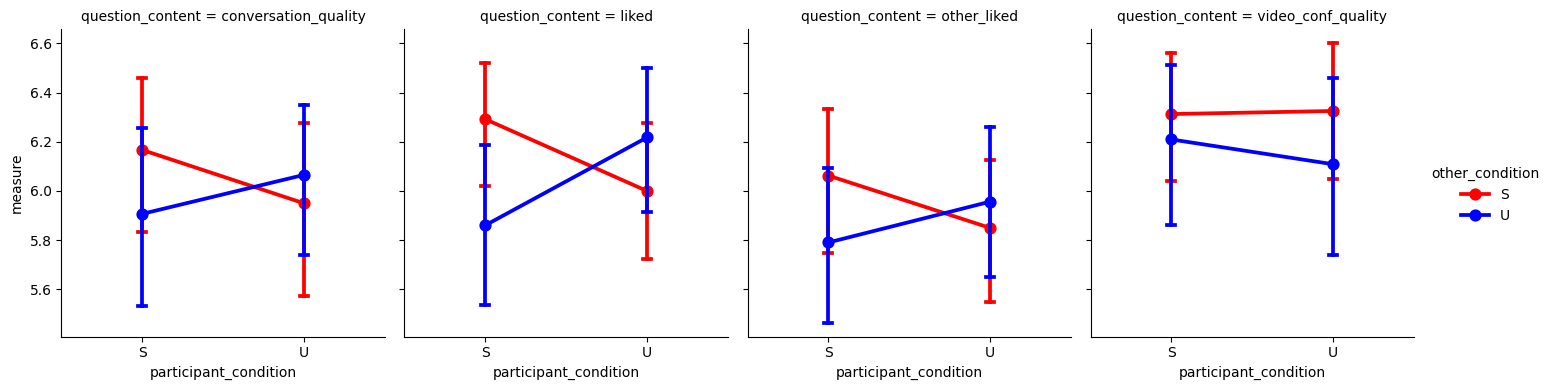

In [17]:
df_analysis = df_analysis.groupby(["sid", "user_id", "participant_condition", "other_condition", "question_content"]).mean(numeric_only=True).reset_index()
print("Number of participants : " + str(len(np.unique(df_analysis["user_id"]))))

sns.catplot(x="participant_condition", y="measure", col="question_content", units="user_id", hue="other_condition"
            , height=4, aspect=0.9, data=df_analysis
            , kind="point", capsize=.05
            , order= ["S", "U"]
            , palette=sns.color_palette(['red', 'blue'])
           )

In [18]:
#Export for GLMM
#behavior columns : 'liked', 'other_liked', 'conversation_quality', 'video_conf_quality', 'second_date'

df_analysis = all_data_df.set_index(["sid", "dyad", "user_id", "other_id", "participant_condition", "other_condition"]).sort_index()
df_analysis = df_analysis[['liked', 'other_liked', 'conversation_quality', 'video_conf_quality']]
df_analysis = df_analysis.loc[df_analysis["video_conf_quality"] > 2] #Exclude communications that didn't go well.
df_analysis = df_analysis.stack().to_frame("measure").reset_index()
df_analysis = df_analysis.rename({"level_6" : "question_content"}, axis=1).reset_index()


df_analysis.head()

df_analysis.to_csv("../data/behavior/all_data_df.csv")

# SRM data

In [19]:
#name conversions
def get_file_without_path(file_name, with_extension=False):
    """
		get the name of a file without its path
	"""
    import os
    base = os.path.basename(file_name)
    if not with_extension:
        base = os.path.splitext(base)[0]
    return base

In [20]:

srm_df = pd.DataFrame()
for file in glob.glob("../data/behavior/srm/*.csv"):
    #all_srm.csv is this notebook's output, not an input
    if file.endswith("all_srm.csv"):
        continue
    df = pd.read_csv(file)
    df = df.dropna()
    file_tag = get_file_without_path(file)
    df["question_content"] = [file_tag for x in range(len(df))]
    
    srm_df = pd.concat([srm_df, df])

srm_df = srm_df.rename({"participant_nb": "user_id"}, axis=1)
srm_df = srm_df.rename({"interacting_partner": "other_id"}, axis=1)
srm_df = srm_df.rename({"group.id": "sid"}, axis=1)
srm_df = srm_df.rename({"relationship": "measure"}, axis=1)

In [21]:
srm_df




,Unnamed: 0,sid,user_id,other_id,dyad,measure,question_content
4,5,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p1,mk:prolific_participant_real_2:1p5,mk:prolific_participant_real_2:1_3,0.796428,video_conf_quality
5,6,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p5,mk:prolific_participant_real_2:1p1,mk:prolific_participant_real_2:1_3,-0.177318,video_conf_quality
8,9,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p1,mk:prolific_participant_real_2:1p7,mk:prolific_participant_real_2:1_5,-1.547898,video_conf_quality
9,10,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p7,mk:prolific_participant_real_2:1p1,mk:prolific_participant_real_2:1_5,-0.787335,video_conf_quality
10,11,mk:prolific_participant_real_2:1,mk:prolific_participant_real_2:1p1,mk:prolific_participant_real_2:1p8,mk:prolific_participant_real_2:1_6,0.611810,video_conf_quality
...,...,...,...,...,...,...,...
349,350,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p5,mk:real_meeting_experiment_prolific:6p4,mk:real_meeting_experiment_prolific:6_19,-0.996730,other_liked
352,353,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p4,mk:real_meeting_experiment_prolific:6p7,mk:real_meeting_experiment_prolific:6_21,0.329427,other_liked
353,354,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p7,mk:real_meeting_experiment_prolific:6p4,mk:real_meeting_experiment_prolific:6_21,0.086583,other_liked
354,355,mk:real_meeting_experiment_prolific:6,mk:real_meeting_experiment_prolific:6p4,mk:real_meeting_experiment_prolific:6p8,mk:real_meeting_experiment_prolific:6_22,0.634994,other_liked


In [22]:
df_analysis = all_data_df.groupby(["user_id", "other_id", "participant_condition", "other_condition" ]).mean(numeric_only=True).reset_index()[["user_id", "other_id", "participant_condition", "other_condition" ]]

srm_df = srm_df.merge(df_analysis, on=["user_id", "other_id"])

Number of participants : 58


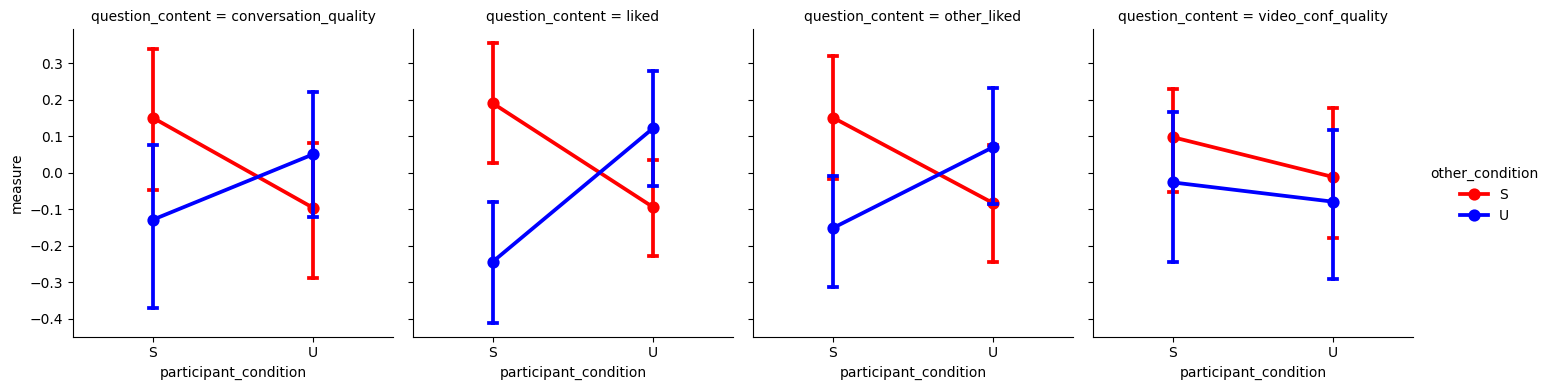

In [23]:
df_analysis = srm_df.groupby(["sid", "user_id", "participant_condition", "other_condition", "question_content"]).mean(numeric_only=True).reset_index()
print("Number of participants : " + str(len(np.unique(df_analysis["user_id"]))))

sns.catplot(x="participant_condition", y="measure", col="question_content", units="user_id", hue="other_condition"
            , height=4, aspect=0.9, data=df_analysis
            , kind="point", capsize=.05
            , order= ["S", "U"]
            , palette=sns.color_palette(['red', 'blue'])
           )


Number of participants : 58


/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"
/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 3}` instead.

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"


/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"
/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 3}` instead.

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"


/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"
/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 3}` instead.

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"


/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"
/var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/ipykernel_78208/3115367601.py:8: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 3}` instead.

  g = sns.catplot( x="participant_condition", y="measure", units="user_id"


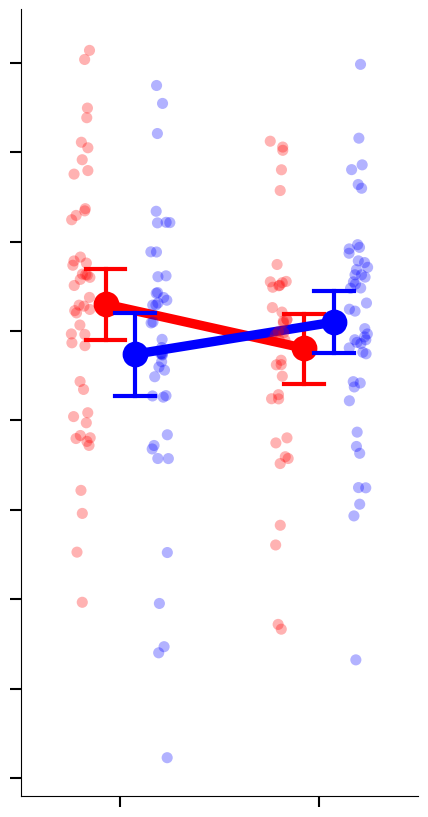

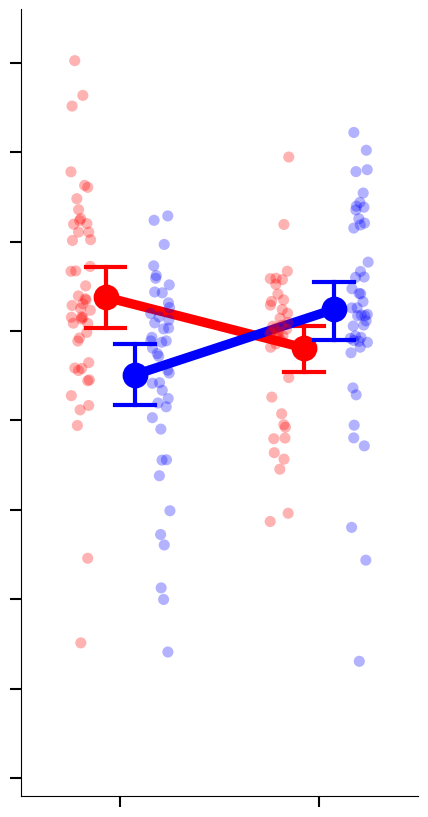

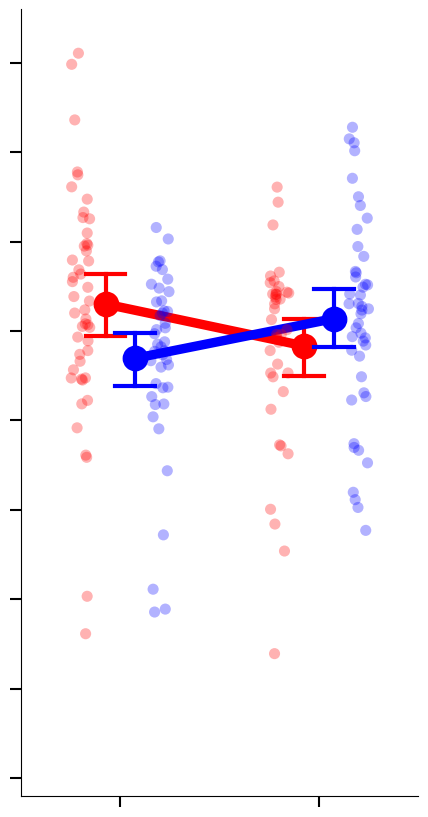

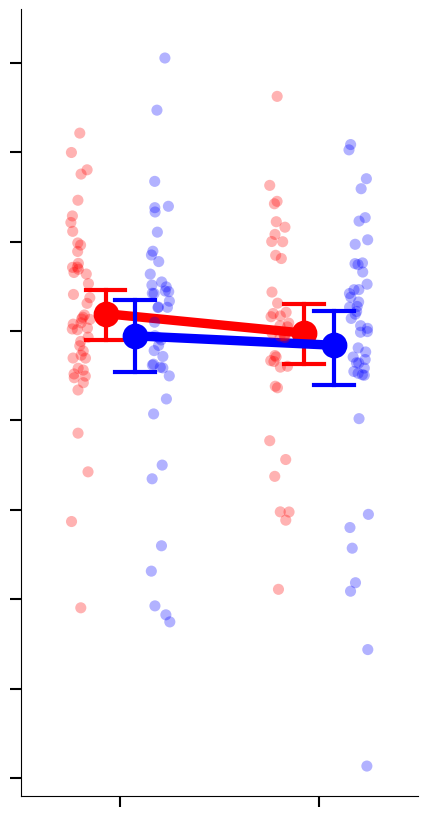

In [24]:
df_analysis = srm_df.groupby(["sid", "user_id", "participant_condition", "other_condition", "question_content"]).mean(numeric_only=True).reset_index()
print("Number of participants : " + str(len(np.unique(df_analysis["user_id"]))))

for question_content in np.unique(df_analysis["question_content"]):
    df_analysis = srm_df.groupby(["sid", "user_id", "participant_condition", "other_condition", "question_content"]).mean(numeric_only=True).reset_index()
    df_analysis = df_analysis.loc[df_analysis["question_content"] == question_content]
    
    g = sns.catplot( x="participant_condition", y="measure", units="user_id"
                        , height=8.6
                        , aspect=0.57
                        , data=df_analysis
                        , kind="point"
                        , capsize=.2
                        , hue="other_condition"
                        , legend=False
                        , scale=2.5
                        , dodge= 0.15
                        , errwidth=3
                        , palette= sns.color_palette(["red", "blue"])
                )
        # Add individual measure points
    sns.stripplot(x="participant_condition", y="measure"
                    , data=df_analysis, hue="other_condition", dodge=0.15, size=8, alpha=0.3, palette=["red", "blue"]
                    , legend=False
                    )    
        
    g.set(ylim=(-2.6, 1.8))
    g.tick_params(labelsize=16, length=8, width=1.5)
    
    plt.savefig("plots/"+question_content+"_legend.pdf", bbox_inches='tight')
    g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
    plt.savefig("plots/"+question_content+".pdf", bbox_inches='tight')    

In [25]:
#For glmm
df_analysis = srm_df.groupby(["sid", "user_id", "other_id", "participant_condition", "other_condition", "question_content"]).mean(numeric_only=True).reset_index()
df_analysis.to_csv("../data/behavior/srm/all_srm.csv")

# Debriefing question

In [26]:
debrief_df = all_data_df[["sid", "user_id", "round", "final_quality", "final_quality_comment", "final_conversation_fidelity", "final_conversation_fidelity_comment", "final_xp_goal", "final_manipulation_comment", "final_manipulation", "final_manipulation_comment", "prolific_id", "share_prolific_id"]]
debrief_df = debrief_df.loc[debrief_df["round"] == 4].drop("round", axis=1)

In [27]:
debrief_df.to_csv("../data/behavior/debrief.csv")